# ☕ Dirty Cafe Sales — Exploratory Data Analysis

Loading → Understanding → Cleaning follows the same step-by-step structure as `agricultue_dataset.ipynb`.
Everything from the EDA section onward keeps the original aesthetic charts and cleaned-dataset export.


# Import Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import os


# Data Loading

In [2]:
data_path = "dirty_cafe_sales.csv"

files = glob.glob(data_path)

# debug check
print("files found:", files)
print("total files:", len(files))


files found: ['dirty_cafe_sales.csv']
total files: 1


In [3]:
df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
print("data loaded successfully")
print("shape:", df.shape)


data loaded successfully
shape: (10000, 8)


# Data Understanding

In [4]:
df.head

<bound method NDFrame.head of      Transaction ID      Item Quantity Price Per Unit Total Spent  \
0       TXN_1961373    Coffee        2            2.0         4.0   
1       TXN_4977031      Cake        4            3.0        12.0   
2       TXN_4271903    Cookie        4            1.0       ERROR   
3       TXN_7034554     Salad        2            5.0        10.0   
4       TXN_3160411    Coffee        2            2.0         4.0   
...             ...       ...      ...            ...         ...   
9995    TXN_7672686    Coffee        2            2.0         4.0   
9996    TXN_9659401       NaN        3            NaN         3.0   
9997    TXN_5255387    Coffee        4            2.0         8.0   
9998    TXN_7695629    Cookie        3            NaN         3.0   
9999    TXN_6170729  Sandwich        3            4.0        12.0   

      Payment Method  Location Transaction Date  
0        Credit Card  Takeaway       2023-09-08  
1               Cash  In-store       2023

In [5]:
df.shape

(10000, 8)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    10000 non-null  str  
 1   Item              9667 non-null   str  
 2   Quantity          9862 non-null   str  
 3   Price Per Unit    9821 non-null   str  
 4   Total Spent       9827 non-null   str  
 5   Payment Method    7421 non-null   str  
 6   Location          6735 non-null   str  
 7   Transaction Date  9841 non-null   str  
dtypes: str(8)
memory usage: 625.1 KB


In [7]:
df.describe()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
count,10000,9667,9862,9821,9827,7421,6735,9841
unique,10000,10,7,8,19,5,4,367
top,TXN_1961373,Juice,5,3.0,6.0,Digital Wallet,Takeaway,UNKNOWN
freq,1,1171,2013,2429,979,2291,3022,159


In [8]:
df.head()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11


In [9]:
df.tail()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
9995,TXN_7672686,Coffee,2,2.0,4.0,NaN,UNKNOWN,2023-08-30
9996,TXN_9659401,NaN,3,NaN,3.0,Digital Wallet,NaN,2023-06-02
9997,TXN_5255387,Coffee,4,2.0,8.0,Digital Wallet,NaN,2023-03-02
9998,TXN_7695629,Cookie,3,NaN,3.0,Digital Wallet,NaN,2023-12-02
9999,TXN_6170729,Sandwich,3,4.0,12.0,Cash,In-store,2023-11-07


In [10]:
# total number of null values in each column
df.isnull().sum()


Transaction ID         0
Item                 333
Quantity             138
Price Per Unit       179
Total Spent          173
Payment Method      2579
Location            3265
Transaction Date     159
dtype: int64

In [11]:
# total number of null values in the whole dataset
df.isnull().sum().sum()


np.int64(6826)

In [12]:
# helps identify repeated rows
df.duplicated().sum()


np.int64(0)

# Data Cleaning

In [13]:
# missing values
print(df.isnull().sum())


Transaction ID         0
Item                 333
Quantity             138
Price Per Unit       179
Total Spent          173
Payment Method      2579
Location            3265
Transaction Date     159
dtype: int64


This dataset marks missing/dirty values with the placeholder strings `"ERROR"` and `"UNKNOWN"` instead of leaving them blank. The first cleaning step is to normalize those into real `NaN` values so pandas' null-handling functions (`isnull()`, `dropna()`, etc.) actually catch them.

In [14]:
df_clean = df.replace(['ERROR', 'UNKNOWN'], np.nan)

# check again
print(df_clean.isnull().sum())


Transaction ID         0
Item                 969
Quantity             479
Price Per Unit       533
Total Spent          502
Payment Method      3178
Location            3961
Transaction Date     460
dtype: int64


In [15]:
# Remove duplicates
df_clean.drop_duplicates(inplace=True)


In [16]:
# check again
print("after removing duplicates:", df_clean.shape)


after removing duplicates: (10000, 8)


In [17]:
df_clean.head()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,NaN,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,NaN,NaN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11


In [18]:
# This line calculates the percentage of missing (null) values in each column of the dataframe.
(df_clean.isnull().sum() / len(df_clean)) * 100


Transaction ID       0.00
Item                 9.69
Quantity             4.79
Price Per Unit       5.33
Total Spent          5.02
Payment Method      31.78
Location            39.61
Transaction Date     4.60
dtype: float64

`Item` is the key field for this dataset (similar to how `Lat` was the key field kept in the agriculture notebook). Rows with no item at all can't be attributed to any product, so those are dropped; everything else is recovered where possible instead of dropped.

In [19]:
df_clean = df_clean[df_clean['Item'].notna()].copy()


In [20]:
df_clean.isnull().sum()

Transaction ID         0
Item                   0
Quantity             420
Price Per Unit       479
Total Spent          452
Payment Method      2877
Location            3583
Transaction Date     418
dtype: int64

In [21]:
(df_clean.isnull().sum() / len(df_clean)) * 100


Transaction ID       0.000000
Item                 0.000000
Quantity             4.650648
Price Per Unit       5.303953
Total Spent          5.004983
Payment Method      31.856937
Location            39.674455
Transaction Date     4.628502
dtype: float64

In [22]:
# Remove duplicates
df_clean.drop_duplicates(inplace=True)


### Fix column data types

`Quantity`, `Price Per Unit`, and `Total Spent` were loaded as text (because of the `ERROR`/`UNKNOWN` strings mixed in), and `Transaction Date` needs to become a real datetime.

In [23]:
# convert numeric columns
for c in ['Quantity', 'Price Per Unit', 'Total Spent']:
    df_clean[c] = pd.to_numeric(df_clean[c], errors='coerce')

# convert to datetime
df_clean['Transaction Date'] = pd.to_datetime(df_clean['Transaction Date'], errors='coerce')


### Recover missing numbers using the relationship `Total Spent = Quantity x Price Per Unit`

Where two of the three values are known, the third can be calculated instead of left missing.

In [24]:
qty, price, total = df_clean['Quantity'], df_clean['Price Per Unit'], df_clean['Total Spent']

mask = total.isna() & qty.notna() & price.notna()
df_clean.loc[mask, 'Total Spent'] = qty[mask] * price[mask]

mask = price.isna() & total.notna() & qty.notna() & (qty != 0)
df_clean.loc[mask, 'Price Per Unit'] = total[mask] / qty[mask]

mask = qty.isna() & total.notna() & price.notna() & (price != 0)
df_clean.loc[mask, 'Quantity'] = total[mask] / price[mask]


In [25]:
# helper time features for later analysis
df_clean['Month'] = df_clean['Transaction Date'].dt.month_name()
df_clean['Weekday'] = df_clean['Transaction Date'].dt.day_name()


In [26]:
df_clean.dtypes

Transaction ID                 str
Item                           str
Quantity                   float64
Price Per Unit             float64
Total Spent                float64
Payment Method                 str
Location                       str
Transaction Date    datetime64[us]
Month                          str
Weekday                        str
dtype: object

In [27]:
df_clean.describe()

,Quantity,Price Per Unit,Total Spent,Transaction Date
count,8996.000000,8999.000000,8994.000000,8613
mean,3.028346,2.950106,8.944241,2023-07-02 03:54:44.012539
min,1.000000,1.000000,1.000000,2023-01-01 00:00:00
25%,2.000000,2.000000,4.000000,2023-04-01 00:00:00
50%,3.000000,3.000000,8.000000,2023-07-02 00:00:00
75%,4.000000,4.000000,12.000000,2023-10-03 00:00:00
max,5.000000,5.000000,25.000000,2023-12-31 00:00:00
std,1.423529,1.279035,6.015763,NaN


In [28]:
# unique values
for col in df_clean.columns:
    print(col)
    print(df_clean[col].nunique())
    print("-" * 30)


Transaction ID
9031
------------------------------
Item
8
------------------------------
Quantity
5
------------------------------
Price Per Unit
6
------------------------------
Total Spent
17
------------------------------
Payment Method
3
------------------------------
Location
2
------------------------------
Transaction Date
365
------------------------------
Month
12
------------------------------
Weekday
7
------------------------------


## Visualization Setup

In [29]:
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.titlesize'] = 15
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['font.family'] = 'DejaVu Sans'

PALETTE = ["#6F4E37", "#C08552", "#EAC4A0", "#A9CBB7", "#557571", "#3D3B30"]
sns.set_palette(sns.color_palette(PALETTE))

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)


## Missing Data Overview

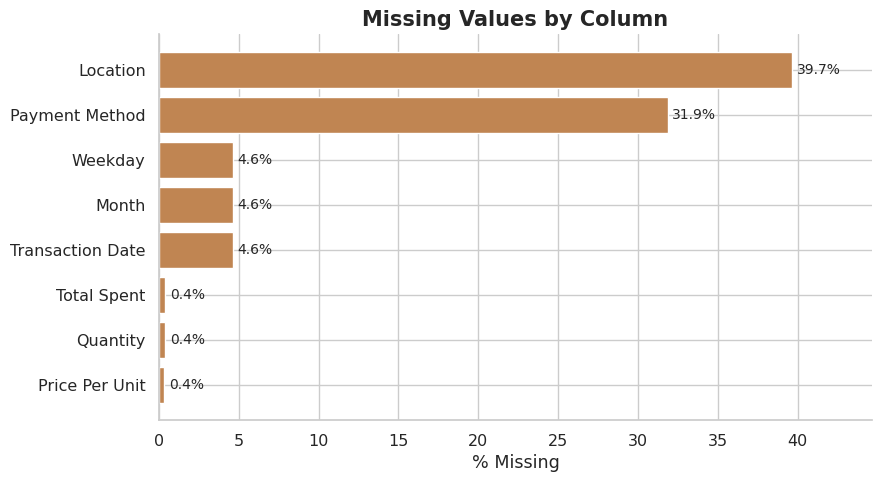

In [30]:
missing = df_clean.isna().mean().sort_values(ascending=False) * 100
missing = missing[missing > 0]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(missing.index[::-1], missing.values[::-1], color=PALETTE[1])
ax.set_xlabel('% Missing')
ax.set_title('Missing Values by Column')
for bar, val in zip(bars, missing.values[::-1]):
    ax.text(val + 0.3, bar.get_y() + bar.get_height()/2, f"{val:.1f}%", va='center', fontsize=10)
ax.set_xlim(0, max(missing.values) + 5)
plt.tight_layout()
plt.show()


## Univariate Analysis

### Item Popularity

/tmp/ipykernel_543/2597891361.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df_clean, y='Item', order=order, palette=PALETTE)
/tmp/ipykernel_543/2597891361.py:3: UserWarning: 
The palette list has fewer values (6) than needed (8) and will cycle, which may produce an uninterpretable plot.
  ax = sns.countplot(data=df_clean, y='Item', order=order, palette=PALETTE)


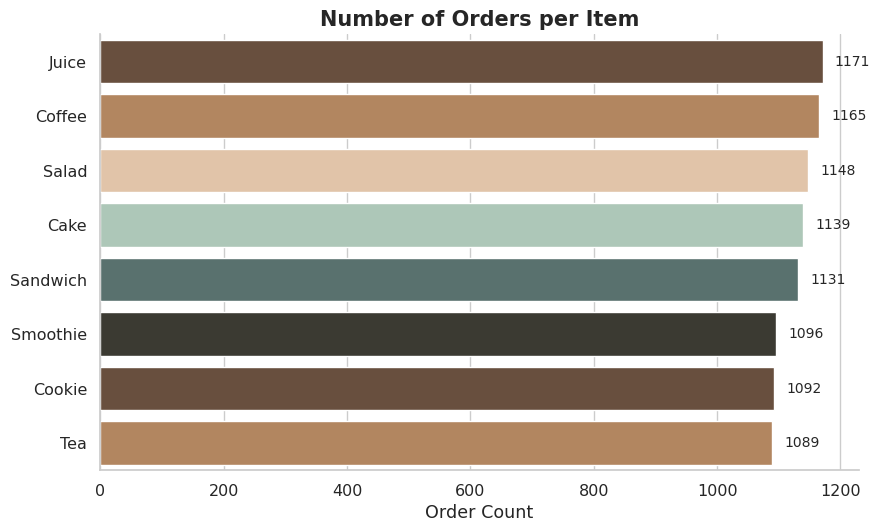

In [31]:
order = df_clean['Item'].value_counts().index
plt.figure(figsize=(9, 5.5))
ax = sns.countplot(data=df_clean, y='Item', order=order, palette=PALETTE)
ax.set_title('Number of Orders per Item')
ax.set_xlabel('Order Count')
ax.set_ylabel('')
for p in ax.patches:
    ax.annotate(f"{int(p.get_width())}", (p.get_width() + 20, p.get_y() + p.get_height()/2),
                va='center', fontsize=10)
plt.tight_layout()
plt.show()


### Payment Method & Location

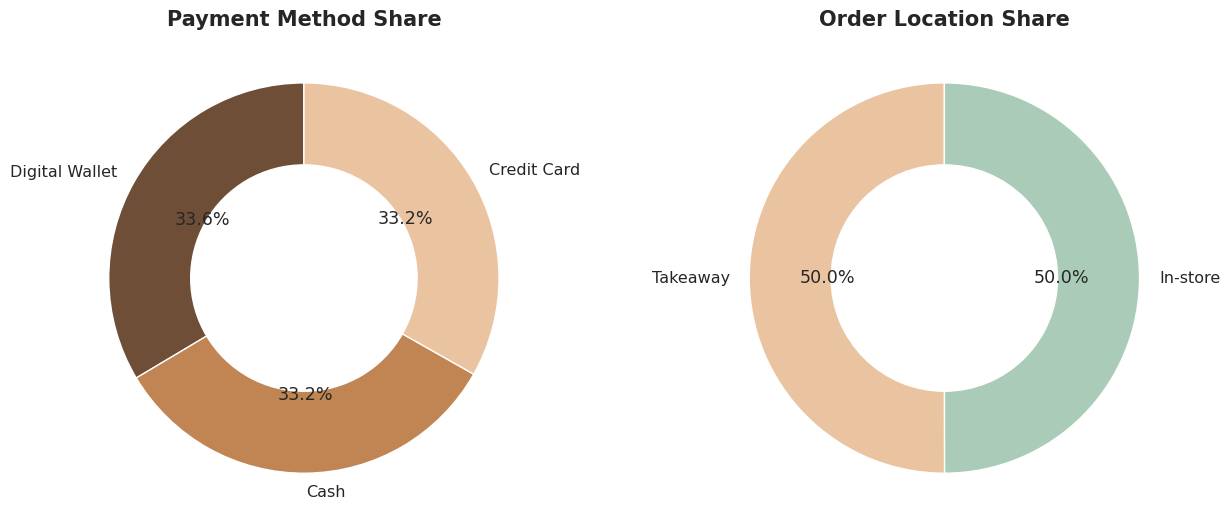

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

pm = df_clean['Payment Method'].value_counts()
axes[0].pie(pm.values, labels=pm.index, autopct='%1.1f%%', startangle=90,
            colors=PALETTE, wedgeprops={'width': 0.42, 'edgecolor': 'white'})
axes[0].set_title('Payment Method Share')

loc = df_clean['Location'].value_counts()
axes[1].pie(loc.values, labels=loc.index, autopct='%1.1f%%', startangle=90,
            colors=PALETTE[2:], wedgeprops={'width': 0.42, 'edgecolor': 'white'})
axes[1].set_title('Order Location Share')

plt.tight_layout()
plt.show()


### Quantity, Price & Total Spent Distributions

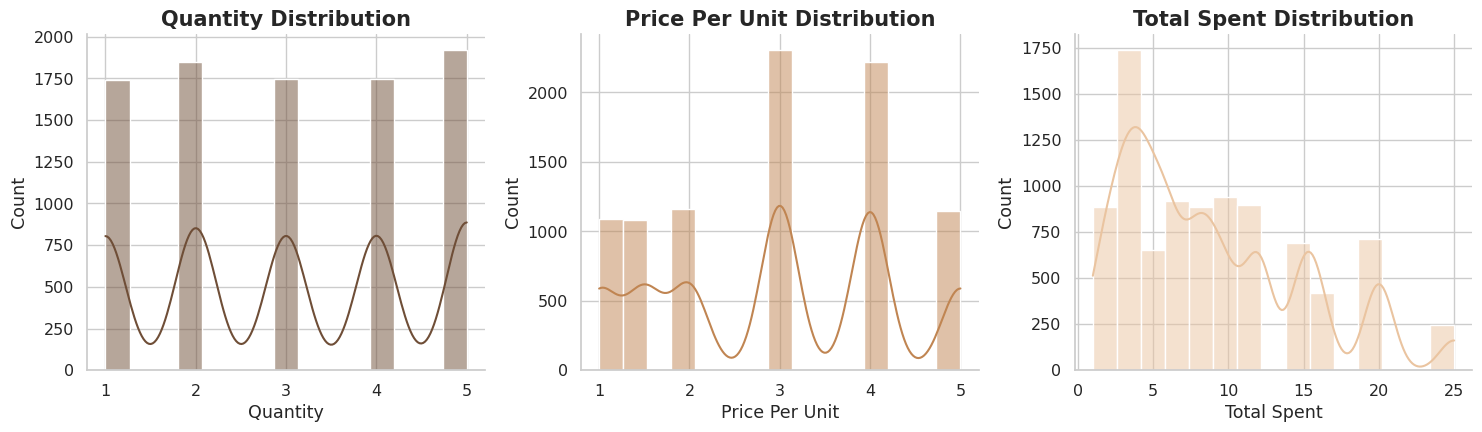

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col, color in zip(axes, ['Quantity', 'Price Per Unit', 'Total Spent'], PALETTE[:3]):
    sns.histplot(df_clean[col].dropna(), bins=15, kde=True, ax=ax, color=color)
    ax.set_title(f'{col} Distribution')
plt.tight_layout()
plt.show()


## Bivariate Analysis

### Revenue by Item

/tmp/ipykernel_543/2927381867.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=rev_by_item.values, y=rev_by_item.index, palette=PALETTE)
/tmp/ipykernel_543/2927381867.py:4: UserWarning: 
The palette list has fewer values (6) than needed (8) and will cycle, which may produce an uninterpretable plot.
  ax = sns.barplot(x=rev_by_item.values, y=rev_by_item.index, palette=PALETTE)


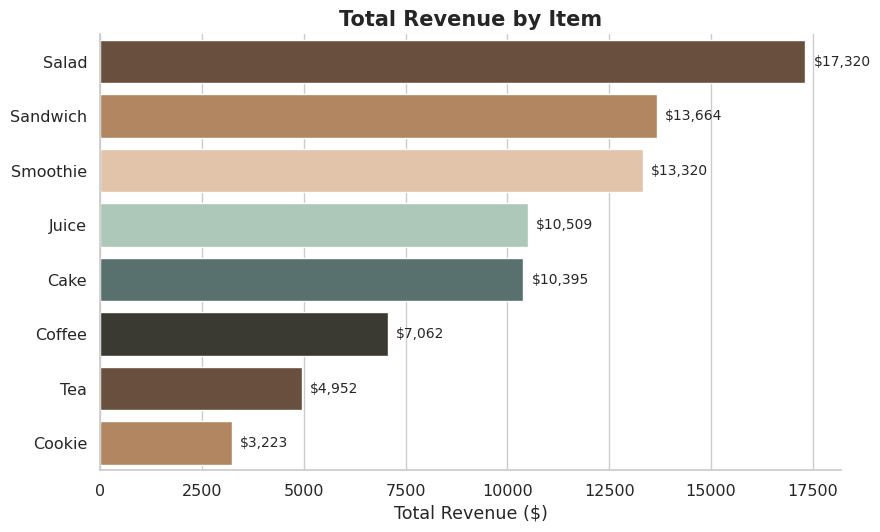

In [34]:
rev_by_item = df_clean.groupby('Item')['Total Spent'].sum().sort_values(ascending=False)

plt.figure(figsize=(9, 5.5))
ax = sns.barplot(x=rev_by_item.values, y=rev_by_item.index, palette=PALETTE)
ax.set_title('Total Revenue by Item')
ax.set_xlabel('Total Revenue ($)')
ax.set_ylabel('')
for p in ax.patches:
    ax.annotate(f"${p.get_width():,.0f}", (p.get_width() + 200, p.get_y() + p.get_height()/2),
                va='center', fontsize=10)
plt.tight_layout()
plt.show()


### Spend Distribution by Payment Method

/tmp/ipykernel_543/4109647142.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(data=df_clean, x='Payment Method', y='Total Spent', palette=PALETTE)
/tmp/ipykernel_543/4109647142.py:2: UserWarning: The palette list has more values (6) than needed (3), which may not be intended.
  ax = sns.boxplot(data=df_clean, x='Payment Method', y='Total Spent', palette=PALETTE)


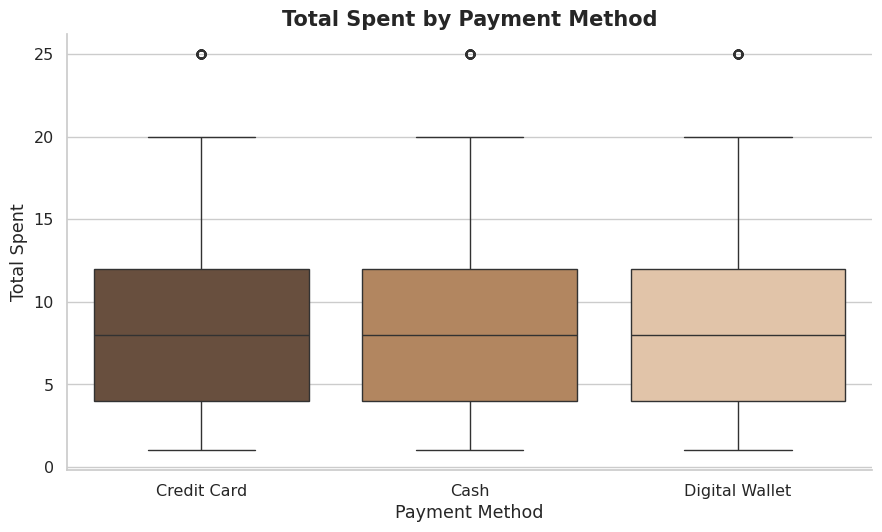

In [35]:
plt.figure(figsize=(9, 5.5))
ax = sns.boxplot(data=df_clean, x='Payment Method', y='Total Spent', palette=PALETTE)
ax.set_title('Total Spent by Payment Method')
plt.tight_layout()
plt.show()


### Average Order Value: In-store vs Takeaway

/tmp/ipykernel_543/1731886420.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=avg_by_loc.index, y=avg_by_loc.values, palette=PALETTE)
/tmp/ipykernel_543/1731886420.py:4: UserWarning: The palette list has more values (6) than needed (2), which may not be intended.
  ax = sns.barplot(x=avg_by_loc.index, y=avg_by_loc.values, palette=PALETTE)


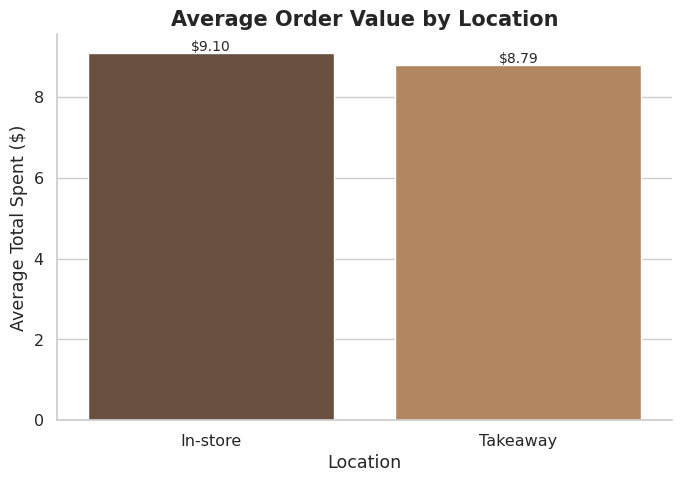

In [36]:
avg_by_loc = df_clean.groupby('Location')['Total Spent'].mean().sort_values(ascending=False)

plt.figure(figsize=(7, 5))
ax = sns.barplot(x=avg_by_loc.index, y=avg_by_loc.values, palette=PALETTE)
ax.set_title('Average Order Value by Location')
ax.set_ylabel('Average Total Spent ($)')
for p in ax.patches:
    ax.annotate(f"${p.get_height():.2f}", (p.get_x() + p.get_width()/2, p.get_height() + 0.05),
                ha='center', fontsize=10)
plt.tight_layout()
plt.show()


## Time-Based Trends

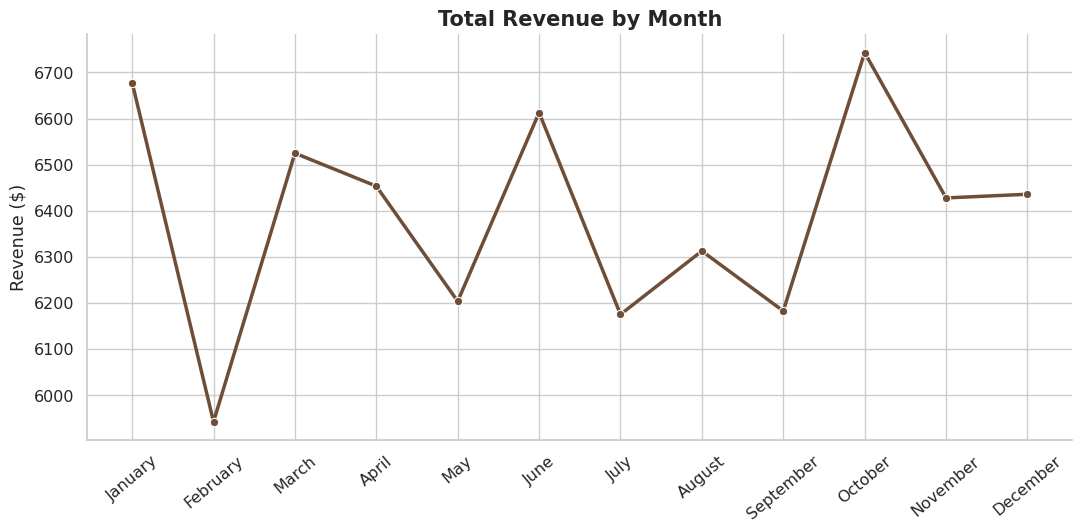

In [37]:
month_order = ['January','February','March','April','May','June',
               'July','August','September','October','November','December']
monthly_rev = df_clean.groupby('Month')['Total Spent'].sum().reindex(month_order)

plt.figure(figsize=(11, 5.5))
ax = sns.lineplot(x=monthly_rev.index, y=monthly_rev.values, marker='o',
                   color=PALETTE[0], linewidth=2.5)
ax.set_title('Total Revenue by Month')
ax.set_ylabel('Revenue ($)')
ax.set_xlabel('')
plt.xticks(rotation=40)
plt.tight_layout()
plt.show()


/tmp/ipykernel_543/1689190396.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=weekday_rev.index, y=weekday_rev.values, palette=PALETTE)
/tmp/ipykernel_543/1689190396.py:5: UserWarning: 
The palette list has fewer values (6) than needed (7) and will cycle, which may produce an uninterpretable plot.
  ax = sns.barplot(x=weekday_rev.index, y=weekday_rev.values, palette=PALETTE)


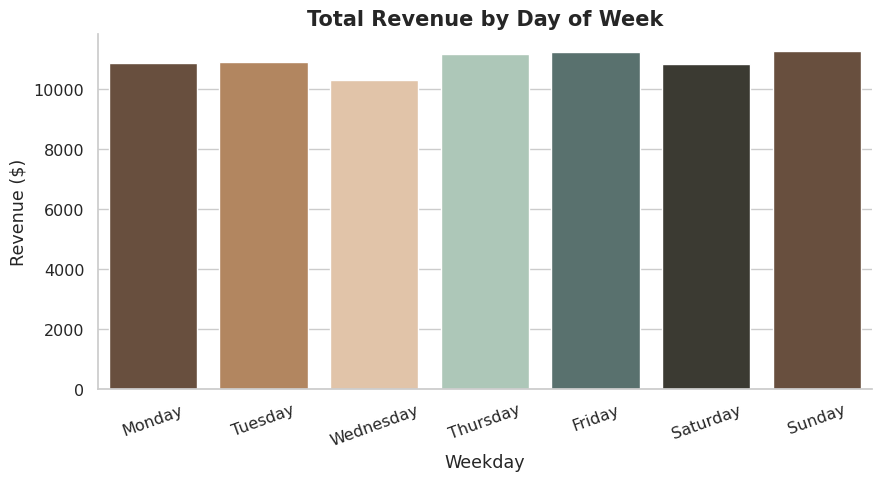

In [38]:
weekday_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
weekday_rev = df_clean.groupby('Weekday')['Total Spent'].sum().reindex(weekday_order)

plt.figure(figsize=(9, 5))
ax = sns.barplot(x=weekday_rev.index, y=weekday_rev.values, palette=PALETTE)
ax.set_title('Total Revenue by Day of Week')
ax.set_ylabel('Revenue ($)')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## Correlation Between Numeric Features

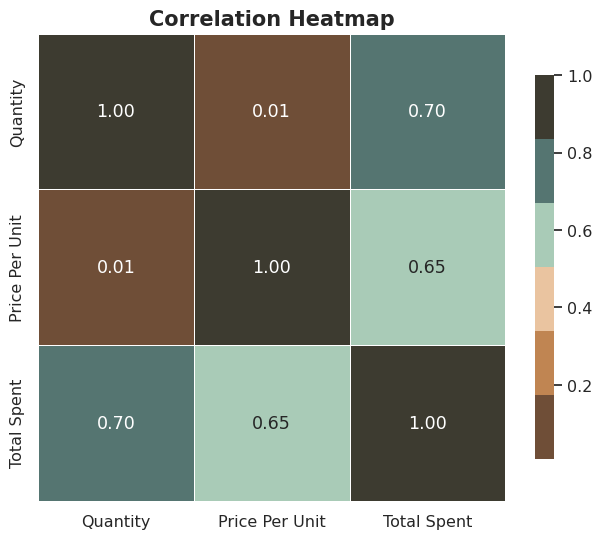

In [39]:
plt.figure(figsize=(6.5, 5.5))
corr = df_clean[['Quantity', 'Price Per Unit', 'Total Spent']].corr()
sns.heatmap(corr, annot=True, cmap=sns.color_palette(PALETTE, as_cmap=True), fmt='.2f',
            linewidths=0.5, square=True, cbar_kws={'shrink': 0.8})
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()


## Key Insights

- The dataset originally marked missing/dirty values with `ERROR`/`UNKNOWN` placeholders instead of blanks; these were normalized to `NaN` and, where possible, **recovered mathematically** using `Total Spent = Quantity x Price Per Unit`.
- Order volume is fairly even across items, with `Revenue by Item` showing which products actually drive the most money (volume != revenue).
- Payment method and location splits show customer preference between **Cash / Credit Card / Digital Wallet** and **In-store / Takeaway**.
- Monthly and weekday revenue trends reveal whether sales are seasonal or flat across the year.
- Numeric correlations confirm the expected strong relationship between `Quantity`, `Price Per Unit`, and `Total Spent`.


## Save the Cleaned & Structured Dataset

Final checks before export:
- Drop exact duplicate rows (if any)
- Round numeric columns for a tidy output
- Keep a clean, logical column order
- Export to a new CSV so the raw file is never overwritten


In [40]:
before = len(df_clean)
df_final = df_clean.drop_duplicates()
print(f"Duplicate rows removed: {before - len(df_final)}")

for c in ['Quantity', 'Price Per Unit', 'Total Spent']:
    df_final[c] = df_final[c].round(2)

df_final = df_final[['Transaction ID', 'Item', 'Quantity', 'Price Per Unit', 'Total Spent',
                      'Payment Method', 'Location', 'Transaction Date', 'Month', 'Weekday']]

df_final.to_csv('cleaned_cafe_sales.csv', index=False)
print(f"Saved cleaned dataset -> cleaned_cafe_sales.csv  ({df_final.shape[0]:,} rows x {df_final.shape[1]} columns)")
df_final.head()


Duplicate rows removed: 0
Saved cleaned dataset -> cleaned_cafe_sales.csv  (9,031 rows x 10 columns)


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date,Month,Weekday
0,TXN_1961373,Coffee,2.0,2.0,4.0,Credit Card,Takeaway,2023-09-08,September,Friday
1,TXN_4977031,Cake,4.0,3.0,12.0,Cash,In-store,2023-05-16,May,Tuesday
2,TXN_4271903,Cookie,4.0,1.0,4.0,Credit Card,In-store,2023-07-19,July,Wednesday
3,TXN_7034554,Salad,2.0,5.0,10.0,NaN,NaN,2023-04-27,April,Thursday
4,TXN_3160411,Coffee,2.0,2.0,4.0,Digital Wallet,In-store,2023-06-11,June,Sunday
